# Phase 3, Step 3: Error analysis (Member A)

**What this notebook does:** looks at **where the best neural models go wrong**, instead of only at averages (this is Step 11 of the methodology). For each dataset it takes the best model (chosen by validation loss) and asks:
- Which traces are hard, and does the model beat "repeat the last value" on most traces?
- Does the error come from sudden changes?
- What do the worst mistakes look like?

**Before you start:** the model notebook must have finished with `QUICK = False`. This notebook only reads its saved results and models, and it doesn't train anything, so it runs in a minute or two.

## 1. Setup
Connects to Drive and holds the settings. Which model to look at is **not** a setting: it is picked automatically (lowest validation loss).

**You should see:** `Device:` and the output folder path.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys, glob, json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ======================= SETTINGS =======================
ROOT     = "/content/drive/MyDrive/dtn_project"
RES      = f"{ROOT}/results"              # the REAL results (not results_quick)
OUT      = f"{RES}/error_analysis"
WINDOW   = 12
SEED     = 0                              # which seed of the best model to look at
BIG      = 0.05                           # "sudden change" = the 5% of steps where the value moved the most
DATASETS = ["5g", "4g", "operator"]
EXP1 = {"5g": ("single", ["DL_bitrate"]), "4g": ("single", ["DL_bitrate"]),
        "operator": ("value+daily", None)}
# ========================================================
os.makedirs(OUT, exist_ok=True)
sys.path.append(ROOT + "/src")
import neural; importlib.reload(neural)
print("Device:", neural.DEVICE, "| output folder:", OUT)

Mounted at /content/drive
Device: cpu | output folder: /content/drive/MyDrive/dtn_project/results/error_analysis


## 2. Load the best models and predict the test data
For each dataset, finds the best model by validation loss, loads the one saved in Step 2, and predicts every test step of every trace. **All numbers here are in the original units** (for 4G and 5G that is kbps).

It also saves every single prediction to `predictions_best_models.csv`.

**You should see:** one line per dataset naming the best model, then `Saved every test prediction`.

In [2]:
def make_windows(arr, window=12, target_idx=0, context=None):
    if context is not None: arr = np.vstack([context[-window:], arr])
    w = np.lib.stride_tricks.sliding_window_view(arr, (window, arr.shape[1]))[:-1, 0]
    return w, arr[window:, target_idx]

def test_windows(ds, names):
    d = f"{ROOT}/processed/{ds}"
    sc = json.load(open(f"{d}/scaler.json"))
    cols = list(range(len(sc["cols"]))) if names is None else [sc["cols"].index(n) for n in names]
    out = {}
    for f in sorted(glob.glob(d + "/*.npz")):
        t = np.load(f)
        out[os.path.basename(f)[:-4]] = make_windows(t["test"][:, cols], WINDOW, context=t["val"][:, cols])
    return out, sc

runs = pd.read_csv(f"{RES}/neural_runs.csv")
parts = []
for ds in DATASETS:
    colset, names = EXP1[ds]
    e1 = runs[(runs.dataset == ds) & (runs.colset == colset) & (runs.window == WINDOW)]
    best_model = e1.groupby("model").best_val.mean().idxmin()        # best by VALIDATION loss
    model, meta = neural.load_model(f"{RES}/models/{ds}__{colset}__{best_model}__s{SEED}.pt")
    test, sc = test_windows(ds, names)
    mu0, sd0 = sc["mean"][0], sc["std"][0]
    for k, (X, y) in test.items():
        p = neural.predict(model, X).astype("float64") * sd0 + mu0
        yt = y.astype("float64") * sd0 + mu0
        last = X[:, -1, 0].astype("float64") * sd0 + mu0
        parts.append(pd.DataFrame(dict(dataset=ds, model=best_model, trace=k,
                                       step=np.arange(len(yt)), y=yt, pred=p, last=last)))
    print(f"{ds}: best model by validation loss = {best_model} (seed {SEED}), {len(test)} test traces")

df = pd.concat(parts, ignore_index=True)
df["err"] = df.pred - df.y                  # model error
df["err_last"] = df["last"] - df.y          # error of "repeat the last value"
df["move"] = df.y - df["last"]              # how much the value really changed in this step
df["se"], df["se_last"] = df.err ** 2, df.err_last ** 2
df.to_csv(f"{OUT}/predictions_best_models.csv", index=False)
print("\nSaved every test prediction to predictions_best_models.csv:", len(df), "rows")

/content/drive/MyDrive/dtn_project/src/neural.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  xb = torch.as_tensor(X[i:i + batch], dtype=torch.float32, device=DEVICE)


5g: best model by validation loss = lstm (seed 0), 79 test traces
4g: best model by validation loss = gru (seed 0), 134 test traces
operator: best model by validation loss = gru (seed 0), 55 test traces

Saved every test prediction to predictions_best_models.csv: 183279 rows


## 3. Which traces are hard?
Scores each trace and compares the model with "repeat the last value". The **ratio** is the model's RMSE divided by the naive RMSE: **below 1 means the model is better**.

You get: the share of traces where the model wins, the 5 best and 5 worst traces, the results by group, and a histogram of the ratios. The groups are the app and Driving/Static for 5G, how the phone moved for 4G (bus, car, and so on), and the signal type for the operator data.

**Look for:** a group that is much worse than the rest (for example moving vs static), and a long tail of bad traces.


=== 5g: 79 traces | model beats 'repeat last value' on 82% of them | median ratio 0.842
worst 5 (model most behind the naive score):
                             trace     rmse  rmse_last   ratio         r2
angerThings__B_2019.11.26_13.00.56  170.308      0.930 183.115 -58947.656
ad__Driving__B_2020.02.14_12.58.17  964.223    436.957   2.207     -1.105
ad__Driving__B_2019.12.14_10.16.30 2982.417   2221.439   1.343      0.277
ickandMorty__B_2019.11.22_07.30.04  529.196    404.298   1.309      0.114
ventureTime__B_2019.11.28_17.18.56 2068.043   1659.207   1.246      0.361
best 5:
                             trace     rmse  rmse_last  ratio     r2
-TheExpanse__B_2019.12.23_10.30.35 3572.716   8102.123  0.441  0.533
-TheExpanse__B_2020.01.03_08.59.40 3844.360   8603.834  0.447  0.539
-TheExpanse__B_2020.01.05_14.55.57 3490.008   6662.136  0.524  0.370
-TheExpanse__B_2020.01.03_10.54.39 4806.487   8019.003  0.599  0.663
-TheExpanse__B_2019.12.06_11.49.24  780.230   1160.882  0.672 -0.067


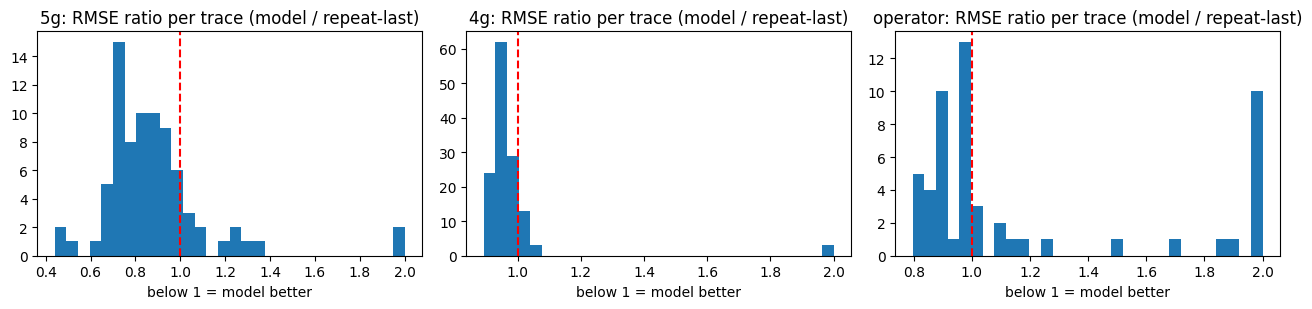

In [3]:
key = ["dataset", "trace"]
df["ydev2"] = (df.y - df.groupby(key).y.transform("mean")) ** 2
g = df.groupby(key)
T = pd.DataFrame(dict(rmse=np.sqrt(g.se.mean()), rmse_last=np.sqrt(g.se_last.mean()),
                      r2=1 - g.se.sum() / g.ydev2.sum().replace(0, np.nan))).reset_index()
T["ratio"] = T.rmse / T.rmse_last            # below 1 = the model beats "repeat last value" on this trace
p = T.trace.str.split("__")
T["group1"] = p.str[0]                       # 5G: app | 4G: how the phone moved | operator: signal type
T["group2"] = np.where(T.dataset == "5g", p.str[1].fillna(""), "")   # 5G: Driving or Static
T.to_csv(f"{OUT}/per_trace_errors.csv", index=False)

for ds in DATASETS:
    t = T[T.dataset == ds]
    print(f"\n=== {ds}: {len(t)} traces | model beats 'repeat last value' on {(t.ratio < 1).mean():.0%} of them "
          f"| median ratio {t.ratio.median():.3f}")
    show = ["trace", "rmse", "rmse_last", "ratio", "r2"]
    print("worst 5 (model most behind the naive score):")
    print(t.sort_values("ratio", ascending=False).head(5)[show].assign(trace=lambda x: x.trace.str[-34:]).round(3).to_string(index=False))
    print("best 5:")
    print(t.sort_values("ratio").head(5)[show].assign(trace=lambda x: x.trace.str[-34:]).round(3).to_string(index=False))

print("\n=== By group (median over traces; ratio below 1 = model better than 'repeat last value')")
print(T.groupby(["dataset", "group1", "group2"]).agg(traces=("trace", "count"), ratio=("ratio", "median"),
                                                   r2=("r2", "median")).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, ds in zip(axes, DATASETS):
    ax.hist(T[T.dataset == ds].ratio.clip(upper=2), bins=30)
    ax.axvline(1, c="red", ls="--"); ax.set_title(f"{ds}: RMSE ratio per trace (model / repeat-last)")
    ax.set_xlabel("below 1 = model better")
plt.tight_layout(); plt.savefig(f"{OUT}/plot_trace_ratio.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Are the errors caused by sudden changes?
Takes the 5% of steps where the value moved the most and checks how much of the total error comes from them. It also shows:
- **move_corr:** does the change the model predicts match the real change? (1 = perfectly, 0 = no relation).
- **move_size_ratio:** how big the model's predicted changes are compared with the real ones. A number far below 1 means the model mostly **repeats the last value** and rarely predicts big moves.

**Look for:** whether a small share of steps causes most of the error, and whether the model reacts to changes at all.

In [4]:
thr = df.groupby("dataset").move.transform(lambda s: s.abs().quantile(1 - BIG))
df["big"] = df.move.abs() >= thr
rows = []
for ds, d in df.groupby("dataset"):
    b, o = d[d.big], d[~d.big]
    pm = d.pred - d["last"]                                   # the move the model predicts
    rows.append(dict(dataset=ds,
        big_steps=f"{len(b) / len(d):.0%} of steps",
        share_of_model_error=f"{b.se.sum() / d.se.sum():.0%}",
        share_of_naive_error=f"{b.se_last.sum() / d.se_last.sum():.0%}",
        rmse_big_model=np.sqrt(b.se.mean()), rmse_big_naive=np.sqrt(b.se_last.mean()),
        rmse_rest_model=np.sqrt(o.se.mean()), rmse_rest_naive=np.sqrt(o.se_last.mean()),
        move_corr=np.corrcoef(pm, d.move)[0, 1],             # does the predicted change match the real change?
        move_size_ratio=pm.std() / d.move.std()))            # how big are the model's moves vs the real ones
S = pd.DataFrame(rows)
S.to_csv(f"{OUT}/sudden_change_summary.csv", index=False)
print("Sudden changes = the", f"{BIG:.0%}", "of steps where the value moved most.\n")
print(S.round(3).T.to_string(header=False))

Sudden changes = the 5% of steps where the value moved most.

dataset                        4g           5g     operator
big_steps             5% of steps  5% of steps  5% of steps
share_of_model_error          62%          77%          75%
share_of_naive_error          66%          93%          82%
rmse_big_model          14457.836    56576.393       78.718
rmse_big_naive            15641.6    79185.969       84.072
rmse_rest_model           2617.04     7053.583       10.452
rmse_rest_naive          2580.419     4931.091        9.064
move_corr                   0.295         0.62        0.257
move_size_ratio             0.292        0.635        0.403


## 5. What the mistakes look like
One typical trace and the worst trace per dataset, around the largest error. **Black is the real value, blue is the model, and the grey dashed line is "repeat the last value".**

**Look for:** a model that is always one step late (blue copying the black line after it moves), or that cannot follow spikes.

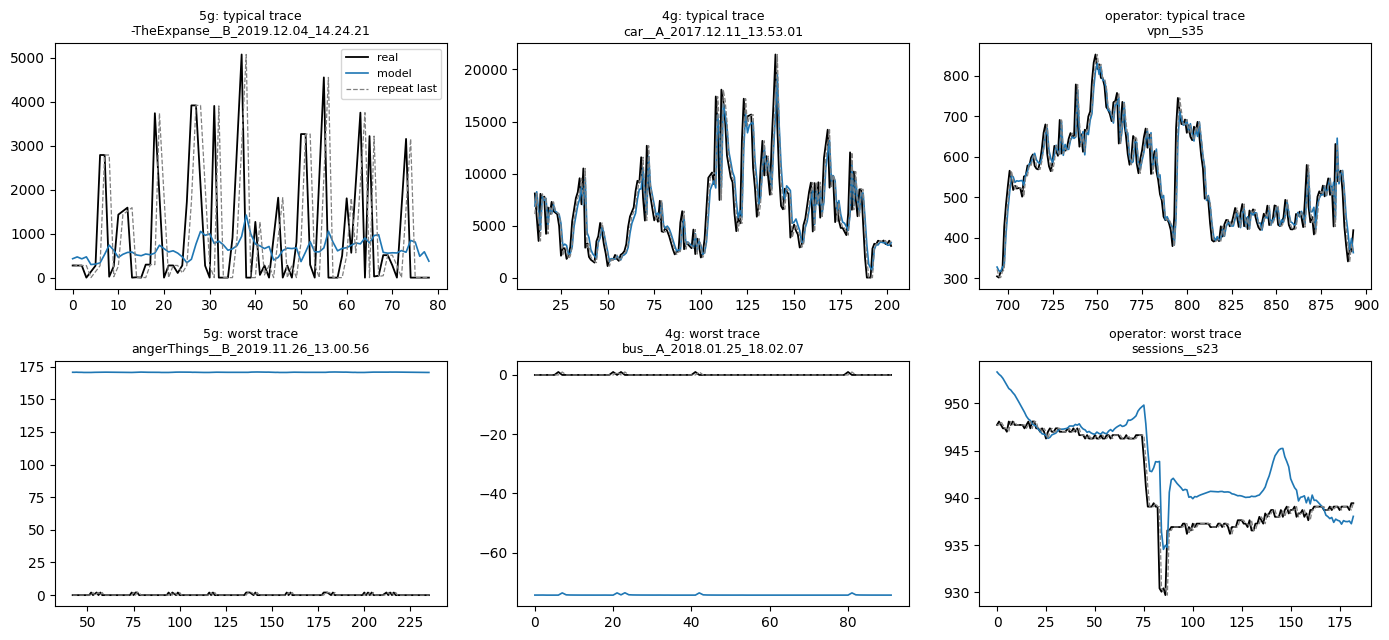

Each plot is centred on the largest error of that trace (x axis: steps of the test part).


In [5]:
def window_plot(ax, d, title, half=100):
    c = int(d.err.abs().values.argmax())                       # centre on the largest error
    s = d.iloc[max(0, c - half): c + half]
    ax.plot(s.step, s.y, c="black", lw=1.3, label="real")
    ax.plot(s.step, s.pred, c="tab:blue", lw=1.2, label="model")
    ax.plot(s.step, s["last"], c="gray", ls="--", lw=0.9, label="repeat last")
    ax.set_title(title, fontsize=9)

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for j, ds in enumerate(DATASETS):
    t = T[T.dataset == ds]
    typical = t.iloc[(t.ratio - t.ratio.median()).abs().argsort().iloc[0]].trace
    worst = t.sort_values("ratio", ascending=False).iloc[0].trace
    for i, (name, tr) in enumerate([("typical trace", typical), ("worst trace", worst)]):
        window_plot(axes[i, j], df[(df.dataset == ds) & (df.trace == tr)].reset_index(drop=True),
                    f"{ds}: {name}\n{tr[-34:]}")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/plot_examples.png", dpi=150, bbox_inches="tight"); plt.show()
print("Each plot is centred on the largest error of that trace (x axis: steps of the test part).")

## 6. The 10 largest errors, one by one
Lists the single worst predictions. The last line says how many different traces they come from: if it is 1 or 2, the large errors are concentrated in a few traces.

In [6]:
for ds, d in df.groupby("dataset"):
    top = d.reindex(d.err.abs().sort_values(ascending=False).index).head(10)
    print(f"\n=== {ds}: the 10 largest model errors")
    print(top[["trace", "step", "y", "pred", "last", "err", "move"]]
          .assign(trace=lambda x: x.trace.str[-30:]).round(1).to_string(index=False))
    print("these 10 come from", top.trace.nunique(), "different trace(s)")


=== 4g: the 10 largest model errors
                         trace  step       y    pred    last      err     move
estrian__A_2017.12.18_04.44.30   501 64298.0  3310.7     0.0 -60987.3  64298.0
    car__A_2018.01.18_12.59.06    79 64095.0  3315.8   126.0 -60779.2  63969.0
estrian__B_2018.01.19_16.06.32   193     0.0 58726.4 63838.0  58726.4 -63838.0
estrian__B_2018.01.19_16.06.32   198 61014.0  4006.8     3.0 -57007.2  61011.0
  train__A_2017.12.18_07.25.15   105 30062.0 82735.5 93587.0  52673.5 -63525.0
    car__A_2018.01.18_14.37.56   203 73803.0 26065.4 24492.0 -47737.6  49311.0
    car__A_2017.12.11_11.52.19   322 69676.0 25739.1 23508.0 -43936.9  46168.0
    car__A_2017.12.07_10.41.37    20 46961.0  5381.4  1073.0 -41579.6  45888.0
    car__A_2018.01.18_12.59.06    74     0.0 41535.7 44434.0  41535.7 -44434.0
  train__A_2018.02.05_15.07.33    36  3433.0 43141.5 46805.0  39708.5 -43372.0
these 10 come from 8 different trace(s)

=== 5g: the 10 largest model errors
                 